# 11. Process crashes and ambiguous write recovery

## Problem

The database commits an approved brief, then the worker exits before reporting success. Reconcile the durable action across a genuinely separate interpreter.

## Learning objectives

Run a controlled crash; inspect committed state; retry by stable action identity; fence a cancelled writer; distinguish effect recovery from process-local concurrency.

Run top to bottom in a fresh kernel. The lab uses actual model calls, tools and temporary local storage. Configure the services before execution. Every plotted value declares its measurement kind.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
os.chdir(ROOT)
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings( deep_lab_mode="live", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "live" and not settings.langfuse_enabled

## Concept explanation

## Checkpoints versus durable jobs

A checkpoint records state from which execution can resume.

Your repository already uses SQLite LangGraph checkpoints and demonstrates that a pending human review can survive recreation of the application service.

However, its asynchronous teaching example uses a process-local thread pool. That is a useful way to demonstrate concurrent work, but a thread pool does not provide durable job ownership.

The two mechanisms solve different problems.

| Mechanism             | Responsibility                                    |
| --------------------- | ------------------------------------------------- |
| LangGraph checkpoint  | Preserve graph execution state                    |
| Persistent job record | Track lifecycle, ownership, deadlines and retries |
| Worker                | Execute or resume tasks                           |
| Lease                 | Temporarily establish which worker owns execution |
| Idempotency key       | Prevent duplicate logical side effects            |
| Application database  | Persist approved business records                 |

A production-oriented design often needs all of them.

## The durable job lifecycle

The application must distinguish "the agent is running" from "the latest HTTP request is still open."

A long-running job should remain identifiable when the requesting client disconnects.

## Persistent job schema

For a focused teaching implementation, SQLite is enough. For multiple distributed workers, PostgreSQL or a dedicated durable workflow service is generally more appropriate.

The important difference from a process-local future is that this record survives worker termination.

## Claiming work safely

Multiple workers must not simply read all `QUEUED` records and start executing them.

They need an atomic claim operation.

### **Code walkthrough**

`BEGIN IMMEDIATE` serializes SQLite write transactions. Two workers using the same database cannot simultaneously acquire the same write transaction.

The lease token identifies the execution attempt.

The lease expiration permits another worker to claim a job if its previous owner disappears.

But lease expiration does **not** prove the previous worker stopped. An old worker may still be running.

That is why later state changes need a conditional check against the current lease token.

This is called *fencing*.

## Fenced completion

If the lease expires and another worker claims the job, the old worker cannot successfully complete the job using its outdated lease token.

For a complete system, lease renewal must use a similar conditional update. Long-running work should periodically check cancellation and deadlines.

A lease only protects operations that actually verify it. An unrelated external API will not automatically honor Northstar's fencing token.

## The exactly-once illusion

Consider an external side effect:

```
1. Worker calls save_brief.
2. Database commits the brief.
3. Worker crashes before recording success.
4. Job restarts.
5. Worker executes save_brief again.
```

The checkpoint may indicate that the save step needs to run again.

Therefore:

**Checkpoints do not guarantee exactly-once external effects.**

A checkpoint and a separate application database do not automatically share one atomic transaction.

The usual engineering approach is to combine at-least-once execution with idempotent effects.

For Northstar, the exact approved action should map to one stable artifact ID.

Retries can then return the existing committed result.

### **Crash scenarios**

| Failure point                       | Possible state                    | Recovery action                             |
| ----------------------------------- | --------------------------------- | ------------------------------------------- |
| Before tool execution               | No side effect                    | Retry                                       |
| During retrieval                    | Unknown read outcome              | Retry bounded read                          |
| Before write commit                 | No committed write                | Retry approved action                       |
| After write commit, before response | Write committed, status uncertain | Reconcile by idempotency key                |
| After checkpoint, before next step  | Checkpoint exists                 | Resume from persisted state                 |
| Worker lease expires                | Previous worker may still run     | Fence stale worker                          |
| Cancellation requested              | Job may be in-flight              | Stop future work and enforce write boundary |

The most important case is the ambiguous write outcome.

It should trigger reconciliation, not an assumption that the operation failed.

## Checkpoints and process restart

The repository's existing restart test is an excellent learning exercise:

1. Start a brief-generation run.
2. Reach the review interrupt.
3. Close the service and checkpoint connection.
4. Recreate them.
5. Resume the same thread with the matching review ID.
6. Confirm the approved brief exists.

The durable job extension adds lifecycle state around that existing behavior.

When restoring a job, the worker inspects both the job record and the graph state.

If the graph is waiting for review, the worker must not restart research from the beginning.

If the graph has completed but the job record is stale, the worker should reconcile the final artifact and update job status.

If the graph is incomplete, it can resume subject to retry and deadline policy.

## Retry policy and cancellation

Not every failure should be retried.

| Failure                    | Retry?                            |
| -------------------------- | --------------------------------- |
| Temporary search timeout   | Yes, within budget                |
| Invalid tool arguments     | Usually no automatic retry        |
| Permission denied          | No                                |
| Missing evidence           | Not indefinitely                  |
| Model output parse error   | Possibly one bounded repair       |
| Write with unknown outcome | Reconcile before retry            |
| Deadline exceeded          | No further work                   |
| User cancellation          | Stop work and prohibit new writes |

A useful retry policy combines maximum attempts, backoff, deadlines, and error classification.

The system must also ensure that cancellation is not simply a prompt saying "please stop."

Before every consequential write, application code should check the current cancellation and authorization state.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

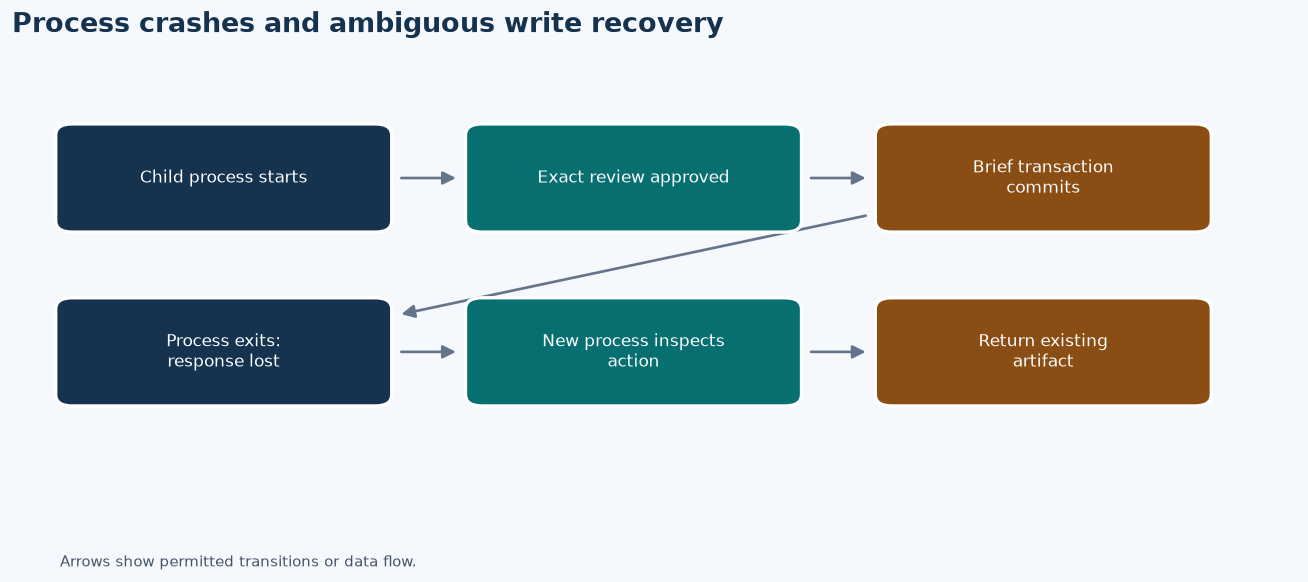

In [2]:
display(diagram('Process crashes and ambiguous write recovery', ['Child process starts', 'Exact review approved', 'Brief transaction commits', 'Process exits: response lost', 'New process inspects action', 'Return existing artifact'], [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import subprocess,sys
from deep_agent_lab.storage import BriefStore
directory = Path(scratch.name)/"crash-store"
directory.mkdir()
child_code = """
import os,sys
from pathlib import Path
from deep_agent_lab.storage import BriefStore
s=BriefStore(Path(sys.argv[1]))
s.propose('stable-action','thread','Readiness','Approved content',{'BKP-7':'4'})
s.decide('stable-action','approve',{'BKP-7':'4'})
s.save_reviewed('thread','Readiness','Approved content',{'BKP-7':'4'})
os._exit(73)
"""
child = subprocess.run([sys.executable,"-c",child_code,str(directory)],capture_output=True,timeout=30)
assert child.returncode == 73
reopened = BriefStore(directory)
assert reopened.review("stable-action")["status"] == "SAVED"
print("Child committed and exited without returning a result.")

Child committed and exited without returning a result.


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Inspect the actual service configuration and returned observations in each cell.

In [4]:
reconciled = reopened.save_reviewed("thread","Readiness","Approved content",{"BKP-7":"4"})
assert reopened.get(reconciled).markdown == "Approved content"
assert reopened.lineage(reconciled)["action_id"] == "stable-action"
with reopened.connect() as db:
    assert db.execute("SELECT count(*) FROM briefs").fetchone()[0] == 1
print("Reconciled existing durable artifact:",reconciled)

Reconciled existing durable artifact: 2e1776132097d23d0d798f4f9ddd5950


## Code walkthrough

The child interpreter calls the actual application store, commits the local review-and-save transaction, then exits abruptly with a controlled exit code. The parent has no artifact response to trust. Its repeat of the exact action looks up SAVED and returns the existing ID. The unique action identity and atomic transition provide the guarantee; the initial read alone would not prevent racing writes. The graph's separate checkpoint may still require replay. AgentService persists reviewer decisions so a crash between authorization and graph resumption can replay the same decision without granting a new action.

## Interactive experiments

Retry the committed action repeatedly, then substitute one character. Only the approved payload may reconcile to the existing artifact.

In [5]:
ids = {reopened.save_reviewed("thread","Readiness","Approved content",{"BKP-7":"4"}) for _ in range(3)}
assert ids == {reconciled}
try:
    reopened.save_reviewed("thread","Readiness","Approved content!",{"BKP-7":"4"})
except PermissionError:
    print("Expected: payload substitution is a new, unapproved action.")
else:
    raise AssertionError("Substituted payload accepted")

Expected: payload substitution is a new, unapproved action.


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
from deep_agent_lab.jobs import JobStore,LeaseLost
from deep_agent_lab.security import Principal
protected = BriefStore(Path(scratch.name)/"fenced")
jobs = JobStore(protected.path)
alice = Principal("northstar","alice")
job = jobs.submit(alice,"save brief")
lease = jobs.claim()
protected.propose("cancel-before-commit",job["thread_id"],"Title","Content",{})
protected.decide("cancel-before-commit","approve",{})
protected.commit_guard = lambda db,thread: jobs.fence(db,job["id"],lease["token"])
jobs.cancel(alice,job["id"])
try:
    protected.save_reviewed(job["thread_id"],"Title","Content",{})
except LeaseLost:
    print("Expected: cancellation won the transaction boundary.")
else:
    raise AssertionError("Cancelled job created a new artifact")

Expected: cancellation won the transaction boundary.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
with protected.connect() as db:
    assert db.execute("SELECT count(*) FROM briefs").fetchone()[0] == 0
assert protected.review("cancel-before-commit")["status"] == "APPROVED"
assert len(ids) == 1

## Exercise

Persist a job in one interpreter and inspect it from another without passing in-memory objects between them. Verify input and owner survive.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
reader_code = """
import sys,json
from pathlib import Path
from deep_agent_lab.jobs import JobStore
from deep_agent_lab.security import Principal
row=JobStore(Path(sys.argv[1])).get(Principal('northstar','alice'),sys.argv[2])
print(json.dumps({'owner':row['owner'],'input':row['input'],'status':row['status']}))
"""
read = subprocess.run([sys.executable,"-c",reader_code,str(jobs.path),job["id"]],
                      check=True,capture_output=True,text=True,timeout=30)
import json
persisted = json.loads(read.stdout)
assert persisted["owner"] == "alice" and persisted["status"] == "CANCELLED"
assert json.loads(persisted["input"])["prompt"] == "save brief"

## Trade-offs and further reading

This queue is a local reference implementation. SQLite is not a distributed worker platform, and a fencing token protects only code that checks it. Long model calls need lease heartbeats at safe boundaries; cancellation prevents new commits but cannot undo an already committed effect.

[Primary source 1](https://docs.langchain.com/oss/python/langgraph/persistence) Â· [Primary source 2](https://docs.langchain.com/oss/python/langgraph/interrupts)

In [9]:
plt.close('all')
scratch.cleanup()
print('All executed module assertions passed.')

All executed module assertions passed.
